# Plot Dispersion Waveforms

Single-event Rayleigh dispersion **waveform panel** plot (narrow-band stacks plus broadband overlay). This notebook:

- Loads per-event results from `output/event_*/`*`_results.json` (metadata and analysis parameters)
- Recomputes `compute_dispersion_curve` when needed (JSON does not store ObsPy streams) or loads a cached `.pkl`
- Plots black (translation) and red (rotation) traces per frequency band (inline matplotlib code, tweakable)
- Adds a **bottom panel** with broadband bandpass **0.02–0.2 Hz** overlays

Run after **03_brs_analysis** for the same event. Set `event_folder` and `data_type` below.

## Imports

In [89]:
import os
import re
import glob
import json
import pickle

import numpy as np
import matplotlib.pyplot as plt
import yaml
from obspy.signal.rotate import rotate_ne_rt
from obspy.signal.cross_correlation import correlate, xcorr_max

from sixdegrees.sixdegrees import sixdegrees

from importlib.machinery import SourceFileLoader
_analysis = SourceFileLoader(
    "brs_analysis", "03_brs_analysis.py"
).load_module()
merge_analysis_params = _analysis.merge_analysis_params
dispersion_compute_kwargs = _analysis.dispersion_compute_kwargs
compute_cross_correlation_lag = _analysis.compute_cross_correlation_lag

## Configuration

In [90]:
# Event date
date = "20240628"

# Event output folder (must contain YAML, mseed, and *_results.json)
event_folder = f"./output/event_{date}"

# "velocity" (Rayleigh: HZ vs JT) or "acceleration" (after differentiation in 03)
data_type = "velocity"

# Broadband panel bandpass (Hz)
bb_fmin = 0.02
bb_fmax = 0.2

# Save figure to ./figures/
save_figure = True
figure_path = "./figures/"



## Load event results JSON

In [91]:
def find_results_json(folder):
    files = glob.glob(os.path.join(folder, "*results.json"))
    if not files:
        raise FileNotFoundError(f"No *results.json in {folder}")
    return files[0]


def find_yaml_config(folder):
    files = glob.glob(os.path.join(folder, "[0-9][0-9][0-9][0-9][0-9][0-9][0-9][0-9].yml"))
    if not files:
        raise FileNotFoundError(f"No YYYYMMDD.yml in {folder}")
    return files[0]


results_path = find_results_json(event_folder)
with open(results_path, "r") as f:
    results = json.load(f)

print(f"Loaded: {results_path}")
print(f"Event: {results['event']}  |  Origin: {results['date']}")

disp_key = (
    "dispersion_curve_velocity"
    if data_type == "velocity"
    else "dispersion_curve_acceleration"
)
if results.get(disp_key) is None:
    raise KeyError(f"No {disp_key} in results JSON — run 03_brs_analysis for this event first.")

baz_theoretical = results.get("backazimuth_velocity", {}).get("theoretical")
if baz_theoretical is None:
    baz_theoretical = results.get("backazimuth_acceleration", {}).get("theoretical")

analysis_params = merge_analysis_params(results.get("analysis_parameters", {}))

Loaded: ./output/event_20240628/event20240628_results.json
Event: event_20240628  |  Origin: 2024-06-28 05:36:36


## Load or compute dispersion results (with streams)

In [92]:
pickle_path = os.path.join(event_folder, f"dispersion_{data_type}.pkl")
sd = None

if os.path.isfile(pickle_path):
    with open(pickle_path, "rb") as f:
        cache = pickle.load(f)
    dispersion_results = cache["dispersion_results"]
    sd = cache.get("sd")
    print(f"Loaded cached dispersion from {pickle_path}")

print(f"Frequency bands: {len(dispersion_results['frequency_bands'])}")

Loaded cached dispersion from ./output/event_20240628/dispersion_velocity.pkl
Frequency bands: 8


## Custom plot: band panels + broadband overlay

In [93]:
def _filter_stream_copy(st, f_lower, f_upper):
    out = st.copy()
    out.detrend("linear")
    out.detrend("demean")
    out.taper(0.05, type="cosine")
    out.filter("bandpass", freqmin=f_lower, freqmax=f_upper, corners=4, zerophase=True)
    out.detrend("demean")
    out.taper(0.05, type="cosine")
    return out

In [94]:
def make_broadband_band(sd_obj, baz_deg, f_lower, f_upper, velocity=None):
    rot = _filter_stream_copy(sd_obj.get_stream("rotation"), f_lower, f_upper)
    tra = _filter_stream_copy(sd_obj.get_stream("translation"), f_lower, f_upper)
    kde_peak = np.nan if velocity is None else float(velocity)
    return {
        "f_lower": f_lower,
        "f_upper": f_upper,
        "baz_used": baz_deg,
        "filtered_rot": rot,
        "filtered_acc": tra,
        "velocities": np.array([]),
        "kde_peak_velocity": kde_peak,
        "kde_deviation": np.nan,
    }

In [95]:
def _format_freq_label(f_lower, f_upper):
    if f_lower < 0.1:
        fl_str = f"{f_lower:.3f}"
    elif f_lower < 1:
        fl_str = f"{f_lower:.2f}"
    else:
        fl_str = f"{f_lower:.1f}"
    if f_upper < 0.1:
        fu_str = f"{f_upper:.3f}"
    elif f_upper < 1:
        fu_str = f"{f_upper:.2f}"
    else:
        fu_str = f"{f_upper:.1f}"
    return f"{fl_str}-{fu_str} Hz"

def _global_translation_peak(broadband_band, wave_type):
    """Max |translation| on broadband panel (reference for global_scaling)."""
    acc = broadband_band["filtered_acc"]
    if wave_type.lower() == "rayleigh":
        return float(np.max(np.abs(acc.select(channel="*Z")[0].data)))
    peaks = [
        float(np.max(np.abs(acc.select(channel=ch)[0].data)))
        for ch in ("*N", "*E")
        if len(acc.select(channel=ch))
    ]
    return max(peaks) if peaks else 1.0

def plot_dispersion_traces_with_broadband(
    dispersion_results,
    broadband_band,
    unitscale="nano",
    data_type="velocity",
    title=None,
    baz_theoretical=None,
    show_errors=False,
    figsize=None,
    broadband_label=None,
    broadband_velocity=None,
    global_scaling=False,
    font=12,
    lw=0.8,
    ylim_pad=1.05,
    text_y_pos=0.8,
    suptitle_y=0.91,
    tra_color="black",
    rot_color="red",
    text_bbox=None,
):
    """Band panels + broadband; translation and rotation on one axis."""
    if text_bbox is None:
        text_bbox = dict(facecolor="white", alpha=0.8, edgecolor="none")
    if "frequency_bands" not in dispersion_results:
        raise ValueError("dispersion_results must contain 'frequency_bands'")
    frequency_bands = list(dispersion_results["frequency_bands"]) + [broadband_band]
    wave_type = dispersion_results.get("wave_type", "rayleigh")
    n_bands = len(frequency_bands)
    if n_bands == 0:
        raise ValueError("No frequency bands to plot")
    # Display scaling (nano: nm/s and nrad; matches notebook convention)
    if data_type.lower() == "velocity":
        if unitscale == "nano":
            acc_scaling, rot_scaling, tra_unit, rot_unit = 1e9, 1e9, "nm/s", "nrad"
        elif unitscale == "micro":
            acc_scaling, rot_scaling, tra_unit, rot_unit = 1e6, 1e6, "µm/s²", "µrad"
        else:
            raise ValueError("unitscale must be 'nano' or 'micro'")
        tra_label_prefix, rot_label_prefix = "v", "r"
        scale_unit = "m/s"
    else:
        if unitscale == "nano":
            acc_scaling, rot_scaling, tra_unit, rot_unit = 1e9, 1e9, "nm/s²", "nrad/s"
        elif unitscale == "micro":
            acc_scaling, rot_scaling, tra_unit, rot_unit = 1e6, 1e6, "µm/s²", "µrad/s"
        else:
            raise ValueError("unitscale must be 'nano' or 'micro'")
        tra_label_prefix, rot_label_prefix = "a", r"$\dot{r}$"
        scale_unit = "m/s²"
    global_tra_peak = (
        _global_translation_peak(broadband_band, wave_type) if global_scaling else None
    )
    if global_scaling and (global_tra_peak is None or global_tra_peak <= 0):
        global_tra_peak = 1.0
    if broadband_velocity is not None:
        broadband_band = dict(broadband_band)
        broadband_band["kde_peak_velocity"] = float(broadband_velocity)
        frequency_bands[-1] = broadband_band
    if figsize is None:
        figsize = (15, 1.3 * n_bands)
    fig, axes = plt.subplots(n_bands, 1, figsize=figsize, sharex=True)
    if n_bands == 1:
        axes = [axes]
    plt.subplots_adjust(hspace=0.0)
    last_acc_filtered = None
    for i, band in enumerate(frequency_bands):
        ax = axes[i]
        for spine in ("bottom", "top", "right", "left"):
            ax.spines[spine].set_visible(False)
        rot_filtered = band["filtered_rot"]
        acc_filtered = band["filtered_acc"]
        last_acc_filtered = acc_filtered
        times = rot_filtered[0].times()
        baz_used = band.get("baz_used")
        if baz_used is None or (isinstance(baz_used, float) and np.isnan(baz_used)):
            backazimuths = band.get("backazimuths", [])
            if len(backazimuths) > 0:
                baz_used = float(np.nanmedian(np.asarray(backazimuths, dtype=float)))
            else:
                raise ValueError(f"No valid backazimuth for panel {i + 1}")
        else:
            baz_used = float(baz_used)
        velocities = band.get("velocities", [])
        if velocities is not None and len(velocities) > 0:
            valid = np.asarray(velocities, dtype=float)
            valid = valid[~np.isnan(valid)]
            if len(valid) > 0:
                velocity_for_scaling = float(np.nanmedian(valid))
                velocity_valid = True
            else:
                velocity_for_scaling = band.get("kde_peak_velocity", np.nan)
                velocity_valid = not np.isnan(velocity_for_scaling)
        else:
            velocity_for_scaling = band.get("kde_peak_velocity", np.nan)
            velocity_valid = not np.isnan(velocity_for_scaling)
        try:
            velocity_for_scaling = float(velocity_for_scaling)
        except (TypeError, ValueError):
            velocity_for_scaling = np.nan
            velocity_valid = False

        velocity_deviation = band.get("kde_deviation", np.nan)
        if wave_type.lower() == "rayleigh":
            tra = acc_filtered.select(channel="*Z")[0].data
            _, rot = rotate_ne_rt(
                rot_filtered.select(channel="*N")[0].data,
                rot_filtered.select(channel="*E")[0].data,
                baz_used,
            )
        elif wave_type.lower() == "love":
            rot = rot_filtered.select(channel="*Z")[0].data
            _, tra = rotate_ne_rt(
                acc_filtered.select(channel="*N")[0].data,
                acc_filtered.select(channel="*E")[0].data,
                baz_used,
            )
        else:
            raise ValueError(f"Unsupported wave_type: {wave_type}")
        if global_scaling:
            tra_scaled = tra / global_tra_peak * acc_scaling
        else:
            tra_scaled = tra * acc_scaling
        rot_scale = velocity_for_scaling if velocity_valid else 1.0
        rot_scaled = rot * rot_scaling * rot_scale
        ax.plot(times, tra_scaled, color=tra_color, lw=lw, label=tra_label_prefix)
        ax.plot(times, rot_scaled, color=rot_color, lw=lw, label=rot_label_prefix)
        tra_max = float(np.max(np.abs(tra_scaled))) if len(tra_scaled) else 0.0
        rot_max = float(np.max(np.abs(rot_scaled))) if len(rot_scaled) else 0.0
        if global_scaling:
            ax.set_ylim(-acc_scaling * ylim_pad, acc_scaling * ylim_pad)
        else:
            panel_max = max(tra_max, rot_max)
            if panel_max > 0:
                ax.set_ylim(-panel_max * ylim_pad, panel_max * ylim_pad)
            else:
                ax.set_ylim(-1, 1)
        ax.set_ylabel("")
        ax.set_yticks([])
        if velocity_valid:
            if show_errors and not np.isnan(velocity_deviation):
                scale_txt = (
                    f"velocity: {velocity_for_scaling:.0f}"
                    f"±{float(velocity_deviation):.0f} {scale_unit}"
                )
            else:
                scale_txt = f"velocity: {velocity_for_scaling:.0f} m/s"
        else:
            scale_txt = "no velocity found"
        ax.text(
            0.02, text_y_pos - 0.1, scale_txt,
            transform=ax.transAxes, fontsize=font - 2, va="center", ha="left", bbox=text_bbox,
        )
        ax.text(
            0.02, abs(1 - text_y_pos + 0.1), f"baz: {baz_used:.1f}°",
            transform=ax.transAxes, fontsize=font - 2, va="center", ha="left", bbox=text_bbox,
        )
        if i == n_bands - 1:
            ax.set_xlabel("Time (s)", fontsize=font)
            if broadband_label is None:
                broadband_label = (
                    f"broadband: {broadband_band['f_lower']:.2f}-"
                    f"{broadband_band['f_upper']:.2f} Hz"
                )
            freq_label = broadband_label
        else:
            freq_label = _format_freq_label(band["f_lower"], band["f_upper"])
        ax.text(
            0.99, text_y_pos - 0.1, freq_label,
            transform=ax.transAxes, fontsize=font - 2, va="center", ha="right", bbox=text_bbox,
        )
        ax.text(
            0.99, abs(1 - text_y_pos + 0.1),
            f"peak {data_type[:3]}: {tra_max:.0f} {tra_unit}",
            transform=ax.transAxes, fontsize=font - 2, va="center", ha="right", bbox=text_bbox,
        )
    axes[-1].spines["bottom"].set_visible(True)
    if title is None and last_acc_filtered is not None:
        start_time = last_acc_filtered[0].stats.starttime
        title = f"{wave_type.capitalize()} waves"
        if baz_theoretical is not None:
            title += f" | BAz = {baz_theoretical:.1f}°"
        title += f" | {start_time.strftime('%Y-%m-%d %H:%M:%S')} UTC"
    fig.suptitle(title, fontsize=font + 2, y=suptitle_y)
    return fig

In [96]:

bands = dispersion_results["frequency_bands"]

baz_median = np.nanmedian([b["baz_used"] for b in bands if b.get("baz_used") is not None])

broadband_band = make_broadband_band(sd, baz_median, bb_fmin, bb_fmax, velocity=2500)

start_time = broadband_band["filtered_acc"][0].stats.starttime


Saved ./figures/dispersion_waveforms_event_20240628.png


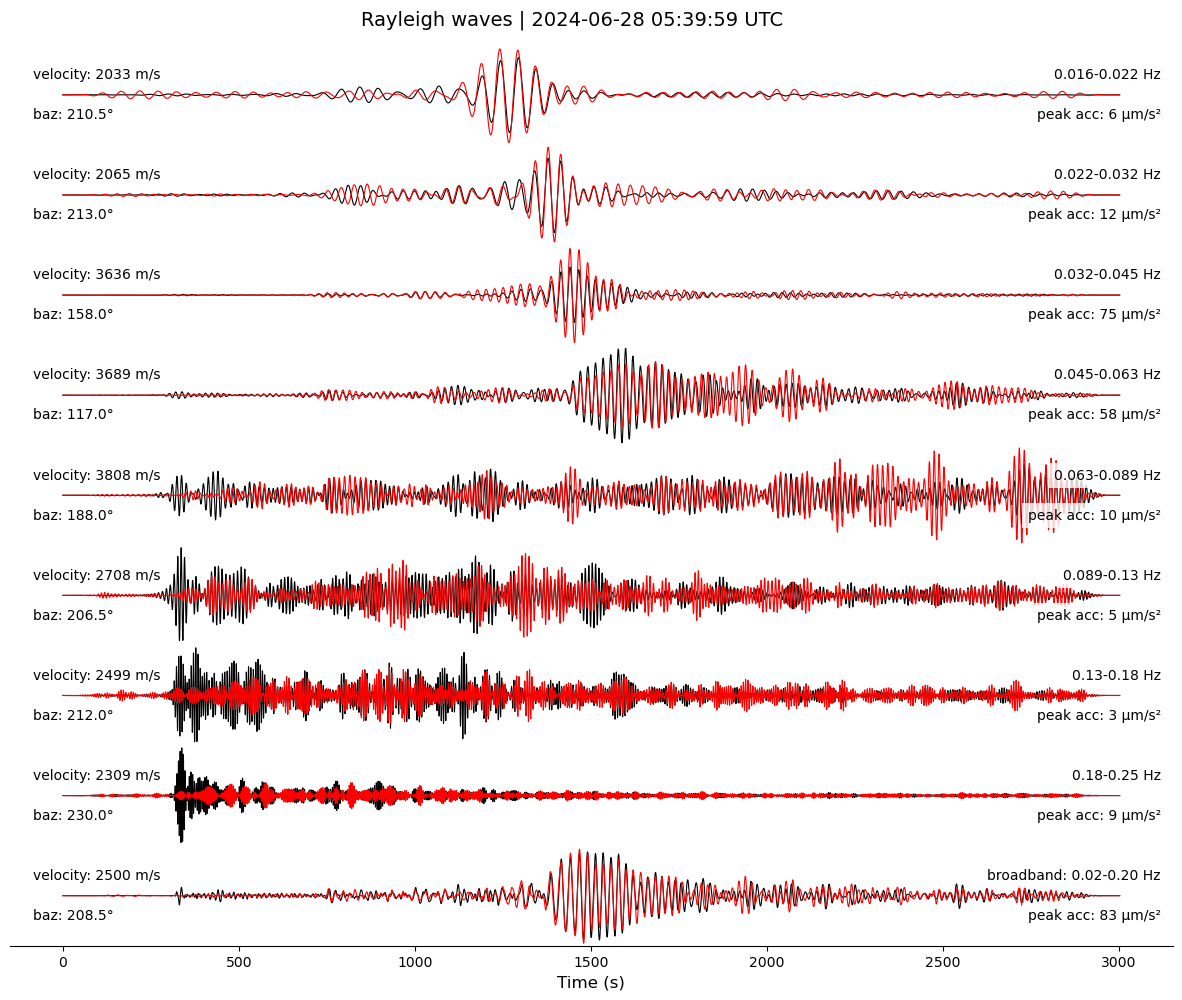

In [97]:
fig = plot_dispersion_traces_with_broadband(
    dispersion_results,
    broadband_band,
    unitscale='micro',
    data_type='acceleration',
    title=f"Rayleigh waves | {start_time.strftime('%Y-%m-%d %H:%M:%S')} UTC",
    baz_theoretical=baz_theoretical,
    show_errors=False,
    broadband_velocity=2500,
)

if save_figure:
    fig.savefig(figure_path+f"dispersion_waveforms_event_{date}.png", bbox_inches="tight", dpi=150)
    print(f"Saved {figure_path}dispersion_waveforms_event_{date}.png")